# Plot Trapezoidal series for the Paper

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import seaborn as sns

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

from pathlib import Path

ROOT = Path("../")

RED = "#FF0055"
BLUE = "#0086FA"

In [2]:
# Specify all the folders containing Kc series
experiments = {
    "data/ca_er1_fede": "CA-ER1",
    "data/us_arm_fede": "US-ARM",
    "data/us_cf1_fede": "US-CF1",
    "data/us_ne1_fede": "US-Ne1",
    "data/villabate_fede": "Villabate",
    "data/castelvetrano_fede": "Castelvetrano"
}

df = []
for folder, name in experiments.items():
    trpz_filepath = ROOT / folder / "data/postprocessed/trapezoidal.pickle"
    data_filepath = ROOT / folder / "data/postprocessed/kc_filtered.pickle"
    # Read Dataframes
    kc = pd.read_pickle(data_filepath)
    trpz = pd.read_pickle(trpz_filepath)
    # Add to cumulative Dataframe
    df.append(trpz.merge(kc, on="Day").set_index("Day").assign(field=name))
    
df = pd.concat(df)
df.head()

,Kc_trapezoidal,Error,Kc,Source,field
Day,,,,,
2016-01-01,0.339818,0.109933,0.274213,Predicted,CA-ER1
2016-01-02,0.339818,0.109933,0.352528,Predicted,CA-ER1
2016-01-03,0.339818,0.109933,0.310868,Predicted,CA-ER1
2016-01-04,0.339818,0.109933,0.479490,Predicted,CA-ER1
2016-01-05,0.339818,0.109933,0.402735,Measured,CA-ER1


In [17]:
def plot_Kc_series(data, field, figsize=(10, 4), ax=None, title=True, xrotation=0):
    if ax:
        fig = None
    else:
        fig, ax = plt.subplots(figsize=figsize)
        
    x = data.index.values
    y = data["Kc"].values
    trpz = data["Kc_trapezoidal"].values
    err = data["Error"].values
    
    if title:
        ax.set_title(field)
        
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=xrotation)
        
    ax.scatter(x, y, s=2, c=BLUE)
    ax.plot(x, trpz, c=RED, lw=1)
    ax.fill_between(x, trpz-err, trpz+err, color=RED, alpha=0.2)
    
    ax.grid(ls='--', alpha=0.5)
    
    return fig if fig else ax


def make_plots(data, fields:list, layout:tuple=(), figsize=(8, 10), show=True, ax_kwargs={}, filename=None):
    if len(layout) == 0:
        layout = len(fields)
    
    fig, axs = plt.subplots(layout, figsize=figsize, layout="tight")
    if len(fields) > 1:
        axs = axs.flatten()
    else:
        axs = [axs]

    for i, field in enumerate(fields):
        data = df.loc[df["field"] == field]
        ax = plot_Kc_series(data, field, ax=axs[i], **ax_kwargs)

    if show:
        plt.show()
    
    if filename is not None:
        fig.savefig(f"{filename}.png", format='png')
        fig.savefig(f"{filename}.eps", format='eps')
        fig.savefig(f"{filename}.pdf", format='pdf')
        
    return fig

# plot_Kc_series(df.loc[df["field"] == "Villabate"], "Villabate")

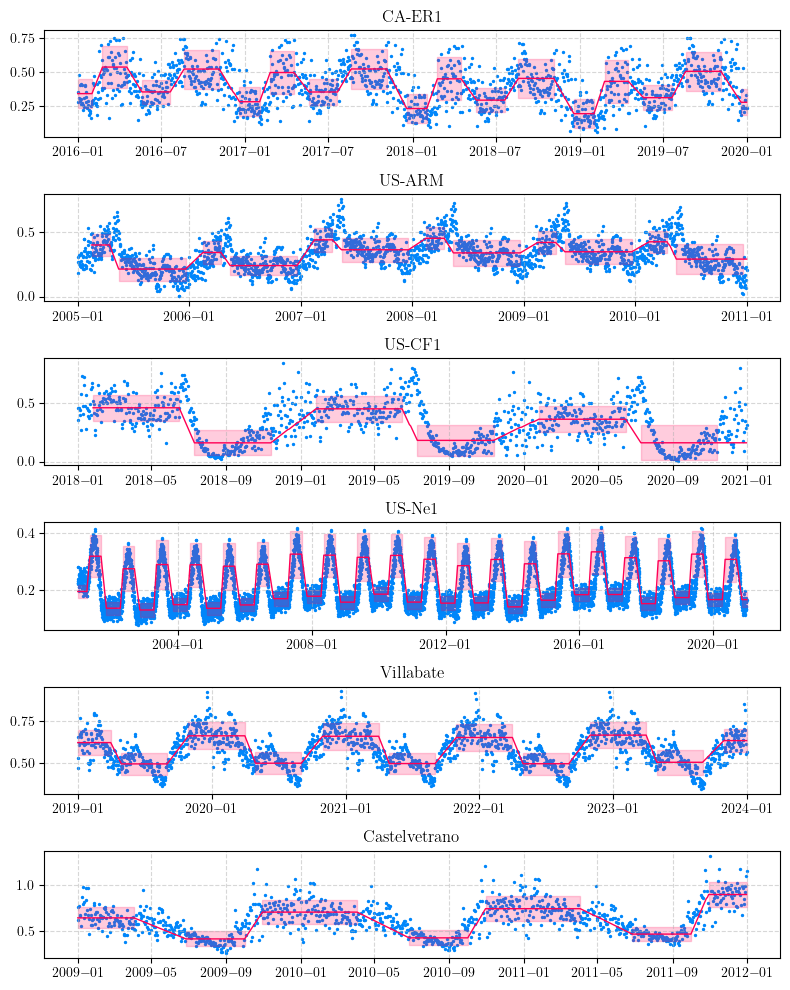

In [13]:
fields = experiments.values()

fig_complete = make_plots(df, fields)

Ca-Er1


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Us-Arm


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Us-Cf1


...

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Villabate


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Castelvetrano


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


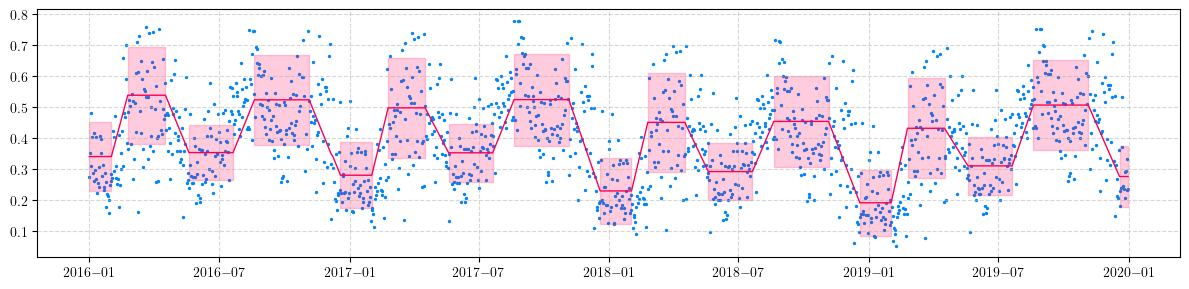

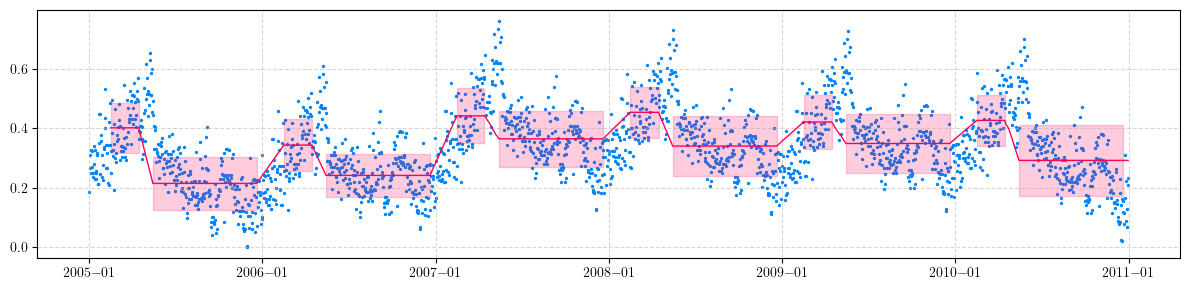

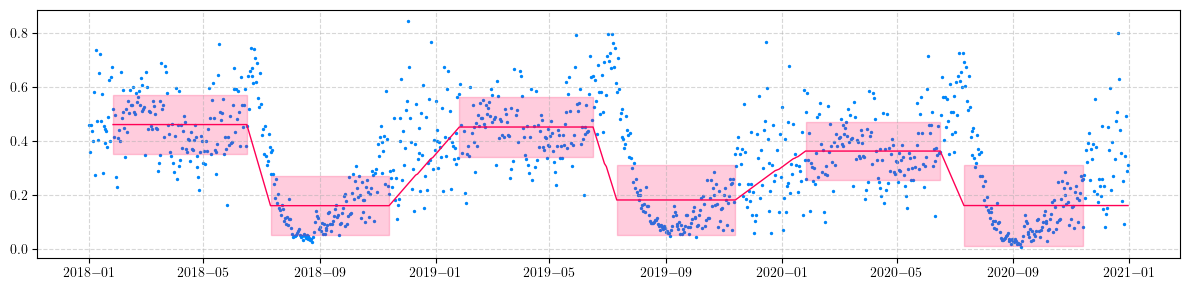

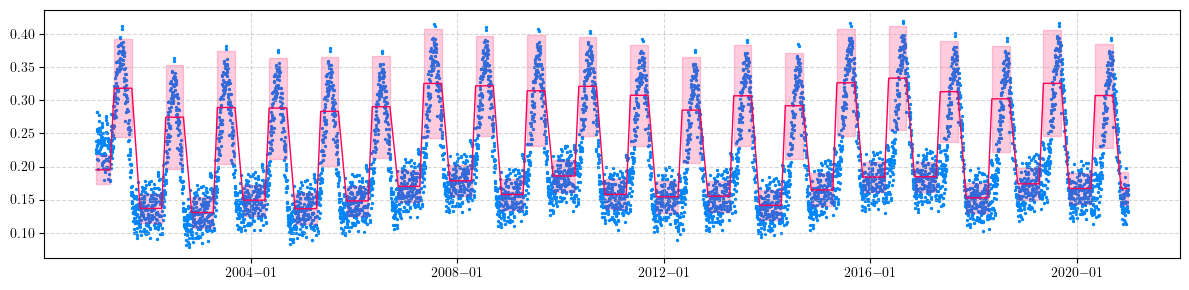

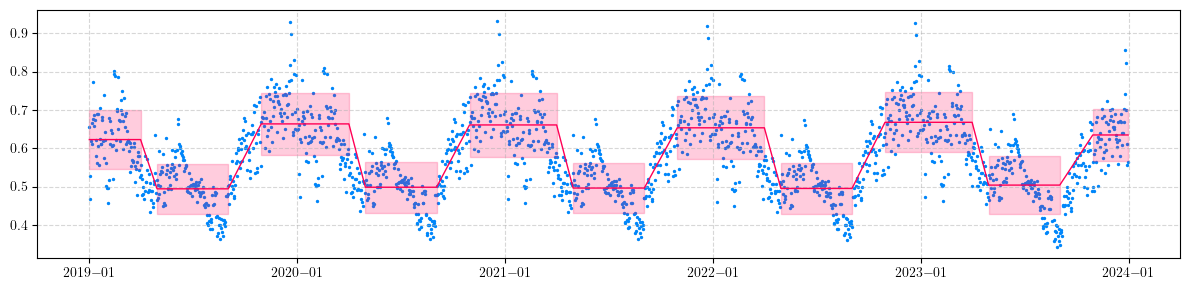

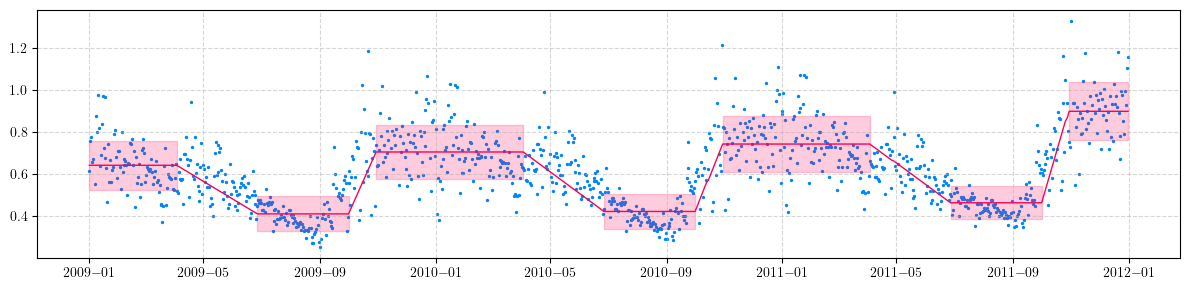

In [18]:
fields = ["Villabate", "Castelvetrano"]

for field in experiments.values():
    print(field.title())
    filename = ROOT / f"visualization/kc-series/{field}_kc"  # Create if do not exists
    fig = make_plots(df, [field], figsize=(12, 3), show=False, ax_kwargs={"title": False}, filename=filename)

# Compare Trapezoidal
Compare our trapezoidal series with the reference series from Allen and Rallo

In [7]:
# Metrics

from sklearn.metrics import r2_score, mean_squared_error, max_error

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def nrmse(y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred)
    
    return rmse / np.mean(y_true)

def mbe(y_true, y_pred):
    """Mean Bias Error"""
    return np.mean(y_true - y_pred)

def pbias(y_true, y_pred):
    """Percent Bias"""
    return 100 * np.sum(y_pred - y_true) / np.sum(y_true)

In [8]:
ref_file = ROOT / "data/external/trapezi.csv"
df_ref = pd.read_csv(ref_file, sep=";", index_col="Day", parse_dates=True, infer_datetime_format=True, dayfirst=True, usecols=lambda x: "Unnamed" not in x )

df_ref

E:\Temp\ipykernel_31440\2654109752.py:2: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df_ref = pd.read_csv(ref_file, sep=";", index_col="Day", parse_dates=True, infer_datetime_format=True, dayfirst=True, usecols=lambda x: "Unnamed" not in x )


,Allen_Villabate,Rallo_Villabate,Allen_Castelvetrano,Rallo_Castelvetrano,Allen_US_ARM,Rallo_US_ARM,Allen_US_Ne1,Rallo_US_Ne1,Allen_US_CF1,Rallo_US_CF1,Allen_CA_ER1,Rallo_CA_ER1
Day,,,,,,,,,,,,
2025-01-01,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.84,0.89,0.6,0.35
2025-01-02,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.85,0.90,0.6,0.35
2025-01-03,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.87,0.91,0.6,0.35
2025-01-04,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.88,0.92,0.6,0.35
2025-01-05,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.89,0.93,0.6,0.35
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-27,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.78,0.84,0.6,0.35
2025-12-28,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.79,0.85,0.6,0.35
2025-12-29,0.9,0.65,0.97,0.65,0.25,0.4,1.2,1.2,0.81,0.86,0.6,0.35


In [9]:
#Extend those series

# Extract only the day and month part of the index
df_ref['day_month'] = df_ref.index.strftime('%m-%d')

# Extend the date range back 10 years
extended_date_range = pd.date_range(start='2000-01-01', end='2025-12-31', freq='D')
extended_df = pd.DataFrame(index=extended_date_range)

# Extract day and month part of the extended index
extended_df['day_month'] = extended_df.index.strftime('%m-%d')

# Merge the extended date range with the original data on day and month
df_extended = extended_df.merge(df_ref, on='day_month', how='left')

# Set the index back to the date range
df_extended.set_index(extended_date_range, inplace=True)
df_extended.drop(columns=['day_month'], inplace=True)
# Drop bissextile day
df_extended.ffill(inplace=True)

df_extended.iloc[58:60]

,Allen_Villabate,Rallo_Villabate,Allen_Castelvetrano,Rallo_Castelvetrano,Allen_US_ARM,Rallo_US_ARM,Allen_US_Ne1,Rallo_US_Ne1,Allen_US_CF1,Rallo_US_CF1,Allen_CA_ER1,Rallo_CA_ER1
2000-02-28,0.9,0.65,0.97,0.65,0.87,0.91,1.2,1.2,1.15,1.15,1.16,1.1424
2000-02-29,0.9,0.65,0.97,0.65,0.87,0.91,1.2,1.2,1.15,1.15,1.16,1.1424


In [10]:
results = {}

for folder, name in experiments.items():
    
    trpz_filepath = ROOT / folder / "data/postprocessed/trapezoidal.pickle"
    data_filepath = ROOT / folder / "data/postprocessed/kc_filtered.pickle"
    # Read Dataframes
    kc = pd.read_pickle(data_filepath)["Kc"]
    trpz = pd.read_pickle(trpz_filepath)
    
    allen = df_extended[f"Allen_{name.replace('-', '_')}"]
    rallo = df_extended[f"Rallo_{name.replace('-', '_')}"]
    # Filter dates
    allen = allen.dropna().reindex(kc.index).values
    rallo = rallo.dropna().reindex(kc.index).values
    kc = kc.values
    
    # Create a tuple key for each experiment-model combination
    results[(name, 'Allen')] = {
        "RMSE": rmse(allen, kc),
        "nRMSE": nrmse(allen, kc),
        "MBE": mbe(allen, kc),
        "MAE": max_error(allen, kc),
        "PBIAS": pbias(allen, kc),
        "R2": r2_score(allen, kc)
    }
    
    results[(name, 'Rallo')] = {
        "RMSE": rmse(rallo, kc),
        "nRMSE": nrmse(rallo, kc),
        "MBE": mbe(rallo, kc),
        "MAE": max_error(rallo, kc),
        "PBIAS": pbias(rallo, kc),
        "R2": r2_score(rallo, kc)
    }

# Convert to DataFrame with MultiIndex
results = pd.DataFrame.from_dict(results, orient='index')
results.index = pd.MultiIndex.from_tuples(results.index, names=['Field', 'Reference'])
# Save Dataframe
results.to_csv(ROOT / "data/postprocessed/performance_comparison.csv", sep=";")

results

RMSE     nRMSE       MBE       MAE      PBIAS  \
Field         Reference                                                      
CA-ER1        Allen      0.561290  0.346191  0.514981  1.122031 -56.589047   
              Rallo      0.510065  0.325330  0.404642  1.122031 -50.599376   
US-ARM        Allen      0.343072  0.235301  0.167912  0.911774 -33.568726   
              Rallo      0.368052  0.222541  0.276415  0.911774 -45.410296   
US-CF1        Allen      0.508703  0.361616  0.383745  1.049620 -53.624284   
              Rallo      0.532439  0.359754  0.456140  1.049620 -57.884867   
US-Ne1        Allen      0.792125  0.677976  0.719191  1.115545 -77.708978   
              Rallo      0.750653  0.694671  0.604844  1.115545 -74.566639   
Villabate     Allen      0.198029  0.053136  0.162181  0.450434 -21.975120   
              Rallo      0.072565  0.009070  0.004748  0.281389  -0.817711   
Castelvetrano Allen      0.251796  0.075966  0.216267  0.595844 -25.912839   
              Rallo      0.142876  0.036106 -0.052956  0.675706   9.366531   

                               R2  
Field         Reference            
CA-ER1        Allen     -3.657881  
              Rallo     -1.003793  
US-ARM        Allen      0.095408  
              Rallo     -0.498098  
US-CF1        Allen     -0.561025  
              Rallo     -1.465299  
US-Ne1        Allen     -7.421171  
              Rallo     -2.770677  
Villabate     Allen     -0.554791  
              Rallo     -0.131617  
Castelvetrano Allen     -2.301404  
              Rallo     -1.727301

In [11]:
results

RMSE     nRMSE       MBE       MAE      PBIAS  \
Field         Reference                                                      
CA-ER1        Allen      0.561290  0.346191  0.514981  1.122031 -56.589047   
              Rallo      0.510065  0.325330  0.404642  1.122031 -50.599376   
US-ARM        Allen      0.343072  0.235301  0.167912  0.911774 -33.568726   
              Rallo      0.368052  0.222541  0.276415  0.911774 -45.410296   
US-CF1        Allen      0.508703  0.361616  0.383745  1.049620 -53.624284   
              Rallo      0.532439  0.359754  0.456140  1.049620 -57.884867   
US-Ne1        Allen      0.792125  0.677976  0.719191  1.115545 -77.708978   
              Rallo      0.750653  0.694671  0.604844  1.115545 -74.566639   
Villabate     Allen      0.198029  0.053136  0.162181  0.450434 -21.975120   
              Rallo      0.072565  0.009070  0.004748  0.281389  -0.817711   
Castelvetrano Allen      0.251796  0.075966  0.216267  0.595844 -25.912839   
              Rallo      0.142876  0.036106 -0.052956  0.675706   9.366531   

                               R2  
Field         Reference            
CA-ER1        Allen     -3.657881  
              Rallo     -1.003793  
US-ARM        Allen      0.095408  
              Rallo     -0.498098  
US-CF1        Allen     -0.561025  
              Rallo     -1.465299  
US-Ne1        Allen     -7.421171  
              Rallo     -2.770677  
Villabate     Allen     -0.554791  
              Rallo     -0.131617  
Castelvetrano Allen     -2.301404  
              Rallo     -1.727301